# 02 · ResNet18: clasificación de presencia de baches (D40)

**Pregunta:** ¿una ResNet18 preentrenada detecta si una foto de carretera contiene al menos un bache (D40) y
mantiene ese desempeño al cambiar de país (Noruega) o de perspectiva (dron, China_Drone)?

La tarea es **clasificación binaria a nivel de imagen** (`has_D40`), no detección de objetos: no se predicen cajas.
Este notebook **no entrena**; lee los artefactos versionados en `reports/` producidos por

```powershell
python -m src.models.train_resnet --config configs/resnet/<experimento>.yaml --device cuda
python -m src.evaluation.cross_domain          # consolidación con EfficientNet y VAE
python -m src.xai.localization --experiments ... # Grad-CAM sobre las mismas imágenes
python -m src.evaluation.inference ...         # latencia (batch 1)
python -m src.evaluation.external_images ...   # fotos externas (Guatemala / EE. UU.)
```

### Protocolo (idéntico para todos los modelos)
- `dataset_v1` congelado (seed 42): train 19,476 · val 4,173 · test_id 4,174 · **test_ood = Noruega** 8,161 · **test_perspective = China_Drone** 2,401.
- Pérdida `BCEWithLogitsLoss` con `pos_weight` calculado **solo en train**; AdamW, lr 1e-4, CosineAnnealing, batch 32.
- **Checkpoint** = época con mayor AP (PR-AUC) en `val`; **umbral** = máximo F1 en `val`. Ambos quedan **congelados**
  para los tres tests: nunca se ajusta nada con test_id, Noruega ni China_Drone.
- Accuracy no se reporta: con ~10 % de prevalencia un modelo que siempre dice "no hay bache" tendría ~90 %.

### Nota de entrenamiento: fp32 en lugar de AMP
En la GPU usada (NVIDIA GTX 1650, 4 GB) la precisión mixta (fp16) desbordó en el forward y dejó NaN en las
estadísticas `running_mean/var` de BatchNorm (`layer4`); `GradScaler` omitía el paso pero BatchNorm ya se había
contaminado y la validación producía scores NaN. Por eso los experimentos usan `amp: false` (sufijo `_fp32`).
Esto **no rompe la comparación**: EfficientNet-B0 se entrenó en Apple MPS, donde el entrenador desactiva AMP, es decir también en fp32.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .3})

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
import sys
sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / "reports" / "experiments" / "resnet"
XAI = PROJECT_ROOT / "reports" / "xai_evaluation"
SPLITS = ["val", "test_id", "test_ood", "test_perspective"]
SPLIT_NAMES = {"val": "Validación", "test_id": "Test interno", "test_ood": "Noruega (OOD)",
               "test_perspective": "China_Drone (dron)"}

DESCRIPTION = {
    "exp1_scratch_fp32": "Desde cero, 224 px",
    "exp2_pretrained_fp32": "ImageNet, 224 px (control)",
    "exp3_augment_fp32": "ImageNet + augmentation, 224 px",
    "exp4_auxiliary_fp32": "ImageNet + tareas auxiliares, 224 px",
    "exp5_res384": "ImageNet, 384 px",
    "exp5_res384_seed43": "ImageNet, 384 px (seed 43)",
    "exp5_res384_seed44": "ImageNet, 384 px (seed 44)",
}

runs = {}
for folder in sorted(RESULTS.glob("*")) if RESULTS.exists() else []:
    if (folder / "metrics.json").exists() and "_limit" not in folder.name:
        runs[folder.name] = dict(
            config=yaml.safe_load((folder / "config.yaml").read_text(encoding="utf-8")),
            metrics=json.loads((folder / "metrics.json").read_text(encoding="utf-8")),
            history=pd.read_csv(folder / "history.csv"),
        )
print("Experimentos encontrados:", ", ".join(runs) or "ninguno todavía")

Experimentos encontrados: exp1_scratch_fp32, exp2_pretrained_fp32, exp3_augment_fp32, exp4_auxiliary_fp32, exp5_res384, exp5_res384_seed43, exp5_res384_seed44


## 1. Experimentos y configuración registrada

Cada experimento cambia **una sola cosa** respecto al control `exp2_pretrained_fp32`. La tabla se lee directamente
de los `config.yaml` guardados al entrenar (incluye versión y hash del dataset).

In [2]:
keys = ["based_on", "pretrained", "augment", "aux_classes", "image_size", "batch_size", "lr", "epochs", "patience",
        "best_epoch", "seed", "amp", "pos_weight", "device", "dataset_version"]
config_table = pd.DataFrame({name: {k: run["config"].get(k) for k in keys} for name, run in runs.items()})
config_table.loc["lr"] = [f"{v:g}" for v in config_table.loc["lr"]]  # lr_fmt: 1e-4, not 0.000
config_table.loc["descripción"] = [DESCRIPTION.get(name, "") for name in config_table.columns]
config_table.loc[["descripción"] + keys]

,exp1_scratch_fp32,exp2_pretrained_fp32,exp3_augment_fp32,exp4_auxiliary_fp32,exp5_res384,exp5_res384_seed43,exp5_res384_seed44
descripción,"Desde cero, 224 px","ImageNet, 224 px (control)","ImageNet + augmentation, 224 px","ImageNet + tareas auxiliares, 224 px","ImageNet, 384 px","ImageNet, 384 px (seed 43)","ImageNet, 384 px (seed 44)"
based_on,None,None,exp2_pretrained_fp32,exp2_pretrained_fp32,exp2_pretrained_fp32,exp2_pretrained_fp32,exp2_pretrained_fp32
pretrained,False,True,True,True,True,True,True
augment,False,False,True,False,False,False,False
aux_classes,[],[],[],"[D00, D10, D20]",[],[],[]
image_size,224,224,224,224,384,384,384
batch_size,32,32,32,32,32,32,32
lr,0.001,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001
epochs,30,15,15,15,15,15,15
patience,6,4,4,4,4,4,4


## 2. Hipótesis de resolución (medida solo con train)

Las fotos de train miden 600–720 px, pero el protocolo base las reduce a 224 × 224. ¿Qué tamaño le queda a un bache?
Se mide el **lado menor de cada caja D40 de train** tras el mismo resize cuadrado usado por el modelo.
No se miran los tests para formular la hipótesis.

In [3]:
from src.data.dataset import MANIFESTS, load_split_frame

train = load_split_frame(splits=["train"])
ann = pd.read_csv(MANIFESTS / "annotations.csv")
ann = ann[(ann["class"] == "D40") & ann.sample_id.isin(train.sample_id)].merge(
    train[["sample_id", "width", "height"]], on="sample_id")
rows = []
for size in (224, 384, 448, 512):
    side = np.minimum(ann.bbox_width / ann.width, ann.bbox_height / ann.height) * size
    rows.append({"resolución": f"{size} px", "mediana lado menor (px)": side.median(),
                 "percentil 25 (px)": side.quantile(.25), "% cajas < 8 px": (side < 8).mean() * 100,
                 "% cajas < 16 px": (side < 16).mean() * 100})
print(f"Train: {train.has_D40.sum()} imágenes con D40, {len(ann)} cajas D40")
print("Tamaños nativos más frecuentes:", train.groupby(["width", "height"]).size().nlargest(3).to_dict())
pd.DataFrame(rows).set_index("resolución").round(1)

Train: 2348 imágenes con D40, 4182 cajas D40
Tamaños nativos más frecuentes: {(600, 600): 9109, (720, 720): 5394, (640, 640): 3363}


,mediana lado menor (px),percentil 25 (px),% cajas < 8 px,% cajas < 16 px
resolución,,,,
224 px,13.1,9.0,17.5,62.7
384 px,22.4,15.4,1.5,26.6
448 px,26.1,18.0,0.6,17.5
512 px,29.9,20.5,0.1,10.4


A 224 px la mitad de los baches queda con menos de ~13 px de lado y tras las 5 reducciones de ResNet (factor 32)
ocupa menos de una celda del mapa final de 7 × 7. A 384 px el mapa final es de 12 × 12 y solo ~27 % de las cajas
queda bajo 16 px. **Hipótesis:** reducir menos la imagen preserva baches pequeños → `exp5_res384`, idéntico al control
salvo `image_size` (batch 32 sigue cabiendo en 4 GB).

## 3. Curvas de entrenamiento

La línea vertical marca la época seleccionada (máxima AP en validación).

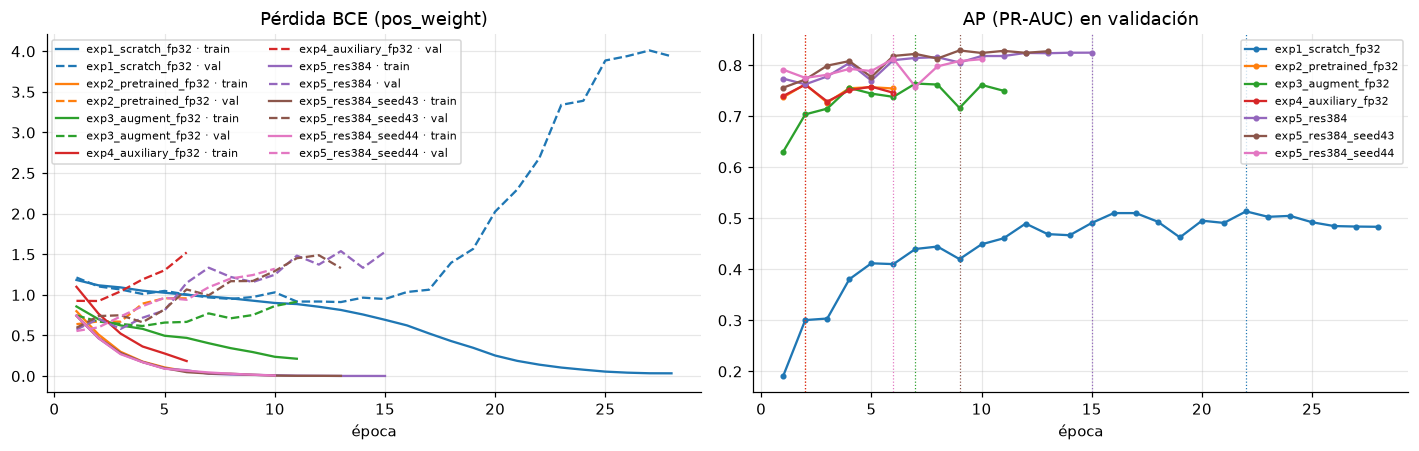

In [4]:
if runs:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for (name, run), color in zip(runs.items(), plt.cm.tab10.colors):
        h = run["history"]
        axes[0].plot(h.epoch, h.train_loss, color=color, label=f"{name} · train")
        axes[0].plot(h.epoch, h.val_loss, "--", color=color, label=f"{name} · val")
        axes[1].plot(h.epoch, h.val_pr_auc, marker="o", ms=3, color=color, label=name)
        axes[1].axvline(run["metrics"]["best_epoch"], color=color, lw=.8, ls=":")
    axes[0].set(title="Pérdida BCE (pos_weight)", xlabel="época")
    axes[1].set(title="AP (PR-AUC) en validación", xlabel="época")
    axes[0].legend(fontsize=7, ncol=2); axes[1].legend(fontsize=7)
    plt.tight_layout(); plt.show()

En todos los casos la pérdida de train cae casi a cero mientras la de validación sube desde las primeras épocas:
el modelo **sobreajusta y se vuelve sobreconfiado**. Aun así la AP de validación (que solo depende del orden de los
scores) puede seguir mejorando; por eso el checkpoint se elige por AP y no por pérdida.

## 4. Métricas por dominio (umbral fijado en validación)

In [5]:
rows = []
for name, run in runs.items():
    for split, m in run["metrics"]["splits"].items():
        c = m["confusion_matrix"]
        rows.append(dict(experimento=name, split=split, n=m["n"], prevalencia=m["prevalence"], precision=m["precision"],
                         recall=m["recall"], f1=m["f1"], ap=m["pr_auc"], tp=c["tp"], fn=c["fn"], fp=c["fp"]))
table = pd.DataFrame(rows)
summary = (table.pivot(index="experimento", columns="split", values=["ap", "f1"]).reindex(columns=SPLITS, level=1)
           .rename(columns=SPLIT_NAMES, level=1))
display(summary.style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold; background-color:#d9f2d9"))
table.round(3)

,experimento,split,n,prevalencia,precision,recall,f1,ap,tp,fn,fp
0,exp1_scratch_fp32,val,4173,0.121,0.441,0.560,0.493,0.514,282,222,357
1,exp1_scratch_fp32,test_id,4174,0.120,0.421,0.540,0.473,0.487,271,231,372
2,exp1_scratch_fp32,test_ood,8161,0.031,0.030,0.148,0.050,0.030,38,218,1231
3,exp1_scratch_fp32,test_perspective,2401,0.027,0.033,0.531,0.063,0.027,34,30,987
4,exp2_pretrained_fp32,val,4173,0.121,0.684,0.714,0.699,0.763,360,144,166
5,exp2_pretrained_fp32,test_id,4174,0.120,0.630,0.665,0.647,0.707,334,168,196
6,exp2_pretrained_fp32,test_ood,8161,0.031,0.100,0.016,0.027,0.054,4,252,36
7,exp2_pretrained_fp32,test_perspective,2401,0.027,0.118,0.594,0.196,0.271,38,26,285
8,exp3_augment_fp32,val,4173,0.121,0.657,0.730,0.692,0.764,368,136,192
9,exp3_augment_fp32,test_id,4174,0.120,0.612,0.677,0.643,0.733,340,162,216


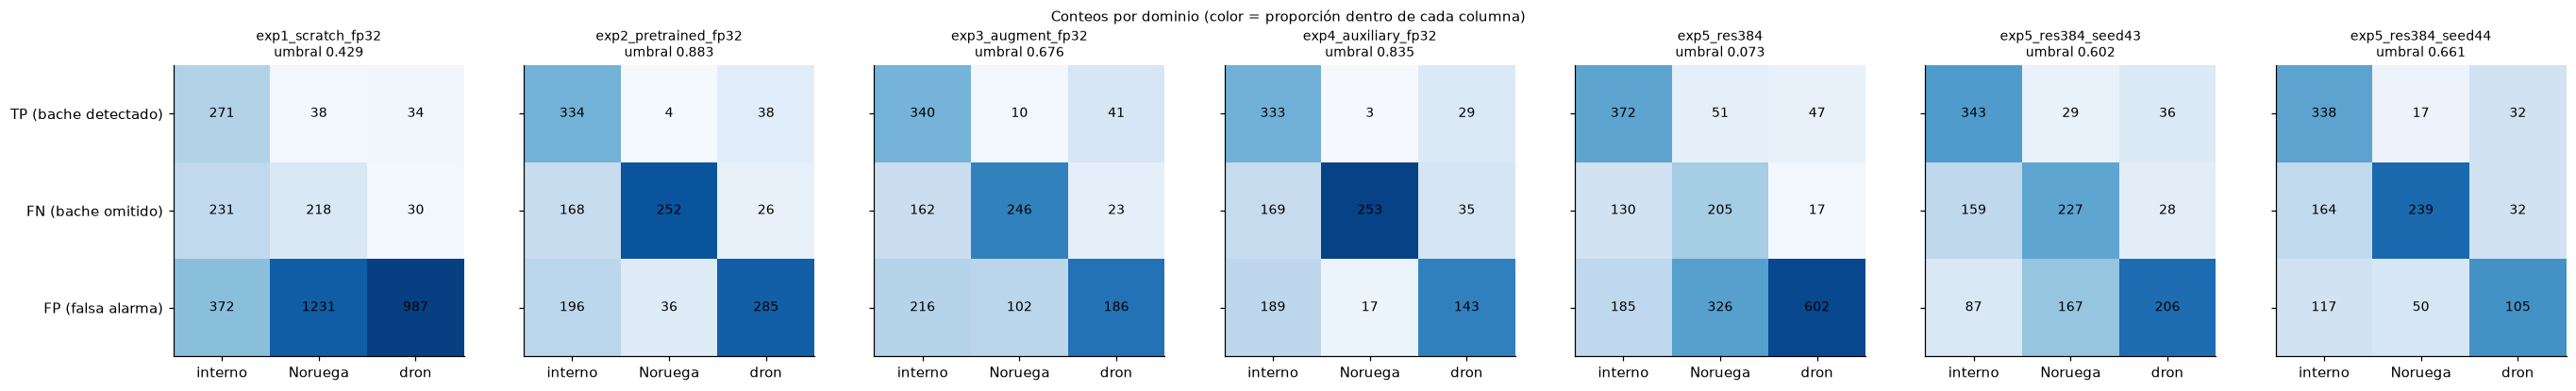

In [6]:
fig, axes = plt.subplots(1, len(runs), figsize=(1.5 + 3.4 * len(runs), 3.6), squeeze=False, sharey=True)
for col, (ax, (name, run)) in enumerate(zip(axes[0], runs.items())):
    grid = np.array([[run["metrics"]["splits"][s]["confusion_matrix"][k] for s in SPLITS[1:]] for k in ("tp", "fn", "fp")])
    ax.imshow(grid / grid.sum(0, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, grid[i, j], ha="center", va="center", fontsize=9)
    ax.set(xticks=range(3), xticklabels=["interno", "Noruega", "dron"], yticks=range(3),
           yticklabels=["TP (bache detectado)", "FN (bache omitido)", "FP (falsa alarma)"])
    ax.set_title(f"{name}\numbral {run['metrics']['threshold']:.3f}", fontsize=9); ax.grid(False)
    if col:
        ax.tick_params(labelleft=False)
fig.suptitle("Conteos por dominio (color = proporción dentro de cada columna)", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Variabilidad entre seeds

Una sola corrida no basta para afirmar que una configuración es mejor. `exp5_res384` se repitió con tres seeds
(42, 43, 44); misma configuración, solo cambia la inicialización de la cabeza, el orden de los batches y dropout/augment.

In [7]:
seed_runs = [n for n in runs if n.startswith("exp5_res384")]
if len(seed_runs) > 1:
    seeds = table[table.experimento.isin(seed_runs)]
    agg = seeds.groupby("split")[["ap", "f1", "recall", "precision"]].agg(["mean", "std"]).reindex(SPLITS)
    agg.index = [SPLIT_NAMES[s] for s in agg.index]
    control = table[table.experimento == "exp2_pretrained_fp32"].set_index("split").reindex(SPLITS)[["ap", "f1"]]
    control.index = agg.index
    control.columns = pd.MultiIndex.from_product([control.columns, ["1 seed"]])
    display(Markdown(f"**exp5 (384 px), media ± desviación estándar sobre {len(seed_runs)} seeds** vs control exp2 (224 px, 1 seed):"))
    display(pd.concat({"exp5 media ± std": agg, "exp2 control": control}, axis=1).round(3))
else:
    print("Solo hay una corrida de exp5; faltan las réplicas con otras seeds.")

**exp5 (384 px), media ± desviación estándar sobre 3 seeds** vs control exp2 (224 px, 1 seed):

exp5 media ± std                                     \
                                 ap            f1        recall          
                               mean    std   mean    std   mean    std   
Validación                    0.822  0.008  0.759  0.013  0.747  0.043   
Test interno                  0.777  0.016  0.715  0.018  0.699  0.037   
Noruega (OOD)                 0.099  0.013  0.132  0.028  0.126  0.067   
China_Drone (dron)            0.321  0.020  0.229  0.093  0.599  0.121   

                                    exp2 control         
                   precision                  ap     f1  
                        mean    std       1 seed 1 seed  
Validación             0.775  0.050        0.763  0.699  
Test interno           0.736  0.065        0.707  0.647  
Noruega (OOD)          0.179  0.065        0.054  0.027  
China_Drone (dron)     0.152  0.081        0.271  0.196

## 6. Comparación con EfficientNet-B0 y el VAE

Tabla consolidada por `src.evaluation.cross_domain` (mismas imágenes, mismas etiquetas, umbral de validación de
cada modelo). El VAE se conserva como resultado negativo: marca casi todas las imágenes como bache.

**AP (PR-AUC) por dominio** — la selección del mejor modelo usa solo la columna Validación:

split,Validación,Test interno,Noruega (OOD),China_Drone (dron)
modelo,,,,
resnet · exp5_res384_seed43,0.829,0.789,0.092,0.330
resnet · exp5_res384,0.825,0.782,0.114,0.298
resnet · exp5_res384_seed44,0.813,0.759,0.091,0.336
efficientnet · efficientnet_b0_pretrained,0.768,0.731,0.059,0.294
resnet · exp3_augment_fp32,0.764,0.733,0.054,0.413
resnet · exp2_pretrained_fp32,0.763,0.707,0.054,0.271
resnet · exp4_auxiliary_fp32,0.762,0.708,0.055,0.267
resnet · exp1_scratch_fp32,0.514,0.487,0.030,0.027
vae · vae_patch512,0.104,0.105,0.048,0.022


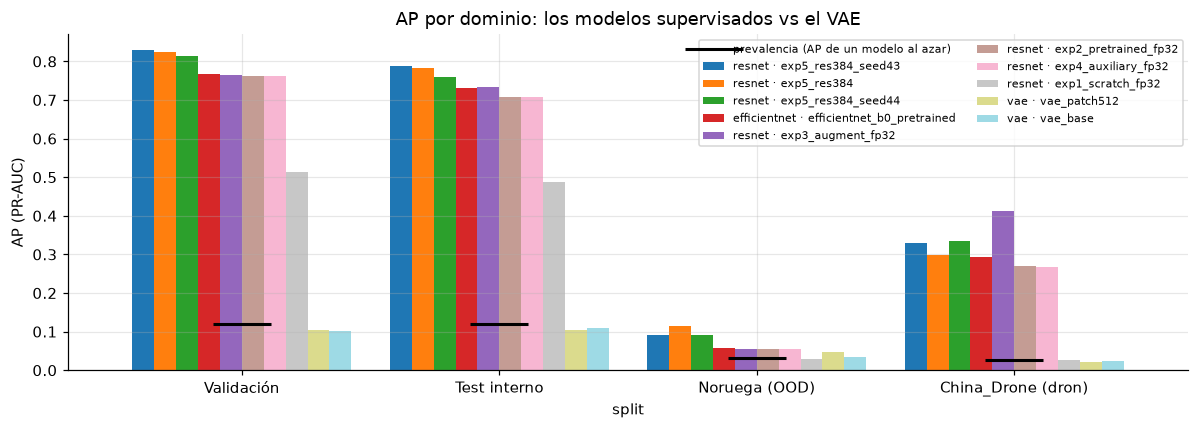

In [8]:
metrics = pd.read_csv(XAI / "metrics.csv")
metrics["modelo"] = metrics.family + " · " + metrics.experiment_id
pivot = (metrics.pivot(index="modelo", columns="split", values="pr_auc").reindex(columns=SPLITS)
         .rename(columns=SPLIT_NAMES).sort_values("Validación", ascending=False))
display(Markdown("**AP (PR-AUC) por dominio** — la selección del mejor modelo usa solo la columna Validación:"))
display(pivot.style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold; background-color:#d9f2d9"))
prevalence = metrics.groupby("split").prevalence.first().reindex(SPLITS)
ax = pivot.T.plot.bar(figsize=(11, 4), rot=0, width=.85, colormap="tab20")
ax.plot(range(4), prevalence.values, "k_", markersize=38, mew=2, label="prevalencia (AP de un modelo al azar)")
ax.set(ylabel="AP (PR-AUC)", title="AP por dominio: los modelos supervisados vs el VAE")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

In [9]:
shift = pd.read_csv(XAI / "domain_shift.csv")
shift["dominio"] = shift.domain.map(SPLIT_NAMES)
shift[["family", "experiment_id", "dominio", "f1_id", "f1_external", "delta_f1", "recall_id", "recall_external",
       "prevalence_external"]].sort_values(["dominio", "f1_external"], ascending=[True, False]).round(3)

,family,experiment_id,dominio,f1_id,f1_external,delta_f1,recall_id,recall_external,prevalence_external
15,resnet,exp5_res384_seed44,China_Drone (dron),0.706,0.318,0.388,0.673,0.500,0.027
7,resnet,exp3_augment_fp32,China_Drone (dron),0.643,0.282,0.361,0.677,0.641,0.027
9,resnet,exp4_auxiliary_fp32,China_Drone (dron),0.650,0.246,0.405,0.663,0.453,0.027
1,efficientnet,efficientnet_b0_pretrained,China_Drone (dron),0.644,0.241,0.404,0.673,0.594,0.027
13,resnet,exp5_res384_seed43,China_Drone (dron),0.736,0.235,0.501,0.683,0.562,0.027
5,resnet,exp2_pretrained_fp32,China_Drone (dron),0.647,0.196,0.451,0.665,0.594,0.027
11,resnet,exp5_res384,China_Drone (dron),0.703,0.132,0.571,0.741,0.734,0.027
3,resnet,exp1_scratch_fp32,China_Drone (dron),0.473,0.063,0.411,0.540,0.531,0.027
19,vae,vae_patch512,China_Drone (dron),0.215,0.058,0.156,0.998,0.844,0.027
17,vae,vae_base,China_Drone (dron),0.217,0.054,0.163,1.000,0.969,0.027


## 7. ¿El modelo mira los baches? Grad-CAM sobre las mismas imágenes

Grad-CAM pondera los mapas de `layer4` por el gradiente del **logit D40** y muestra qué zonas empujan la decisión.
Para comparar modelos de forma justa se explican **todas las imágenes con bache de los tres tests (822)** con cada
modelo, y se mide contra las cajas D40 oficiales:

- **masa en cajas**: fracción de la activación dentro de las cajas D40;
- **masa / área**: lo anterior dividido por el área de las cajas (1 = igual que un mapa uniforme, >1 = se concentra en los baches);
- **pico en caja**: el punto más activo cae dentro de un bache.

Es un diagnóstico de localización aproximado (no IoU ni prueba causal). El mapa final es de 7 × 7 (224 px) o
12 × 12 (384 px), por lo que no puede marcar con precisión baches de pocos píxeles.

positives  recall  box_area_fraction  \
experiment_id        dominio                                                    
exp2_pretrained_fp32 Test interno            502.0   0.665              0.011   
                     Noruega (OOD)           256.0   0.016              0.001   
                     China_Drone (dron)       64.0   0.594              0.015   
exp5_res384          Test interno            502.0   0.741              0.011   
                     Noruega (OOD)           256.0   0.199              0.001   
                     China_Drone (dron)       64.0   0.734              0.014   

                                         mass_in_boxes  mass_over_area  \
experiment_id        dominio                                             
exp2_pretrained_fp32 Test interno                0.033           2.810   
                     Noruega (OOD)               0.000           0.000   
                     China_Drone (dron)          0.054           3.839   
exp5_res384          Test interno                0.033           3.048   
                     Noruega (OOD)               0.000           0.000   
                     China_Drone (dron)          0.052           3.530   

                                         peak_in_box  peak_in_box_TP  \
experiment_id        dominio                                           
exp2_pretrained_fp32 Test interno              0.171           0.201   
                     Noruega (OOD)             0.011           0.000   
                     China_Drone (dron)        0.274           0.289   
exp5_res384          Test interno              0.070           0.089   
                     Noruega (OOD)             0.020           0.098   
                     China_Drone (dron)        0.159           0.170   

                                         peak_in_box_FN  
experiment_id        dominio                             
exp2_pretrained_fp32 Test interno                 0.109  
                     Noruega (OOD)                0.011  
                     China_Drone (dron)           0.250  
exp5_res384          Test interno                 0.016  
                     Noruega (OOD)                0.000  
                     China_Drone (dron)           0.125

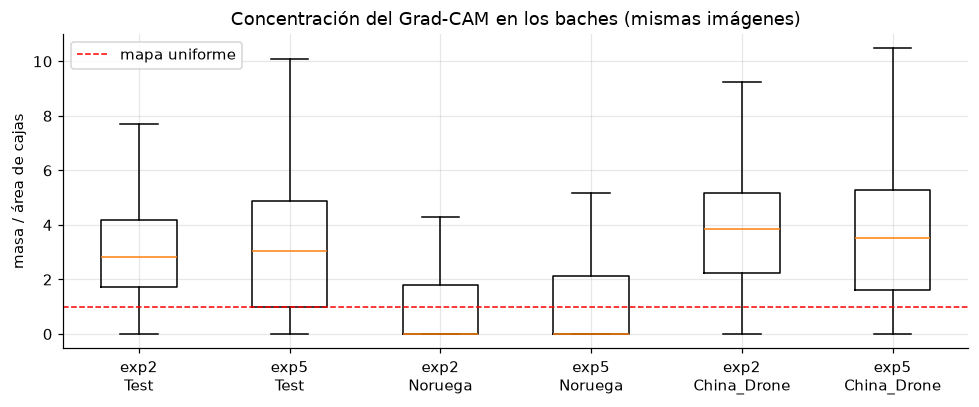

In [10]:
loc_dir = XAI / "localization"
if (loc_dir / "summary.csv").exists():
    loc = pd.read_csv(loc_dir / "summary.csv")
    loc["dominio"] = loc.split.map(SPLIT_NAMES)
    display(loc.set_index(["experiment_id", "dominio"]).drop(columns="split").round(3))
    per_image = pd.read_csv(loc_dir / "per_image.csv")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    data = [per_image[(per_image.experiment_id == e) & (per_image.split == s)].mass_over_area.dropna()
            for s in SPLITS[1:] for e in per_image.experiment_id.unique()]
    labels = [f"{e.split('_')[0]}\n{SPLIT_NAMES[s].split(' ')[0]}" for s in SPLITS[1:] for e in per_image.experiment_id.unique()]
    ax.boxplot(data, tick_labels=labels, showfliers=False)
    ax.axhline(1, color="red", ls="--", lw=1, label="mapa uniforme")
    ax.set(ylabel="masa / área de cajas", title="Concentración del Grad-CAM en los baches (mismas imágenes)")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Falta ejecutar: python -m src.xai.localization --experiments ...")

Imágenes con bache **elegidas al azar** (seed 42, sin mirar el resultado de los modelos), explicadas por cada
modelo. Verde = cajas D40 oficiales; colores cálidos = mayor activación Grad-CAM.

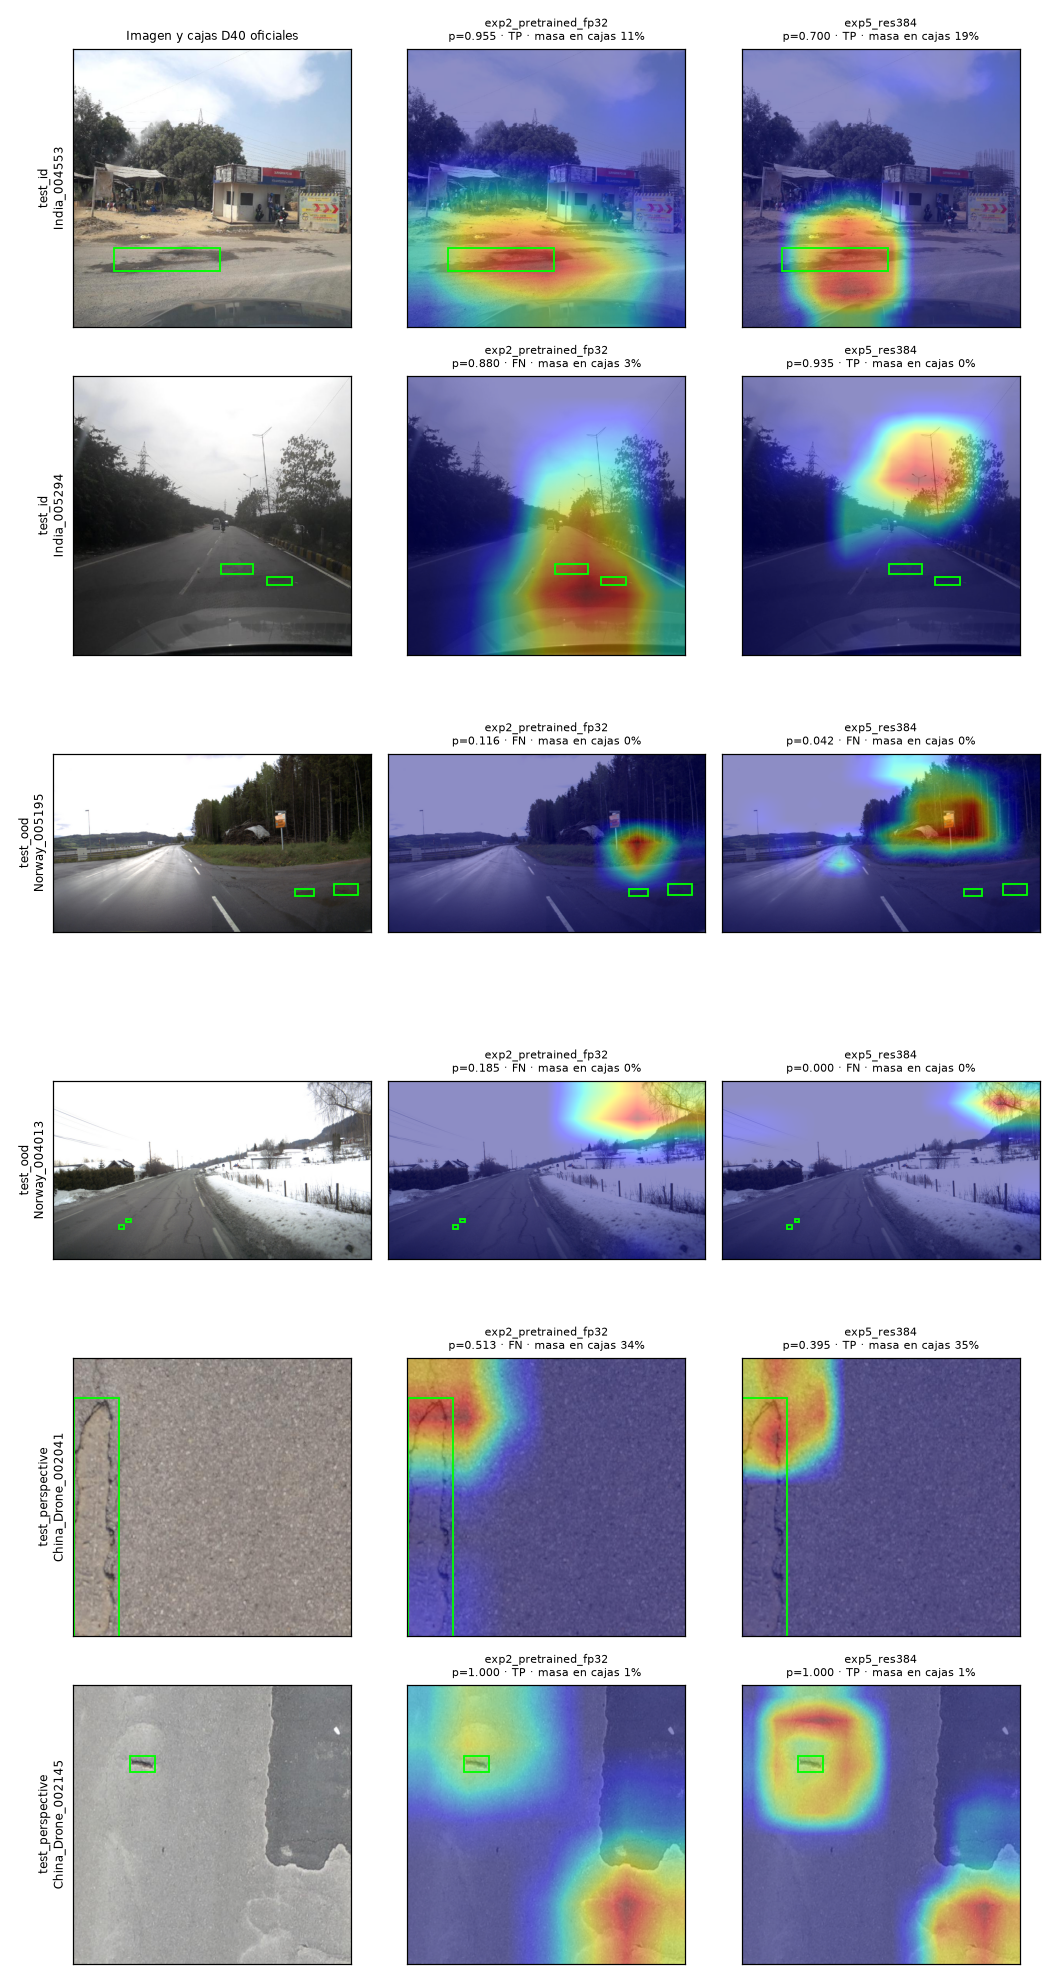

In [11]:
if (loc_dir / "same_images.png").exists():
    display(Image(filename=str(loc_dir / "same_images.png"), width=900))

## 8. Latencia de inferencia (misma máquina)

`src.evaluation.inference`: batch 1, 20 calentamientos, 200 mediciones sobre los mismos IDs de test_id, 4 hilos CPU;
mide forward + score D40 (sin lectura de archivo ni preprocesamiento). Medido en la GTX 1650 / CPU del equipo de
entrenamiento. La latencia de EfficientNet-B0 se midió en un Apple M4 Pro y **no** es comparable con estas cifras.

In [12]:
lat = []
for path in sorted(XAI.glob("*/benchmark_*/latency.json")):
    j = json.loads(path.read_text(encoding="utf-8"))
    if path.parts[-3] in runs:
        lat.append(dict(experimento=path.parts[-3], dispositivo=j.get("device"), mediana_ms=j.get("median_ms"),
                        p95_ms=j.get("p95_ms"), imagen=f"{runs[path.parts[-3]]['config']['image_size']} px"))
pd.DataFrame(lat).pivot(index=["experimento", "imagen"], columns="dispositivo", values=["mediana_ms", "p95_ms"]).round(2) \
    if lat else "Sin benchmarks todavía"

mediana_ms       p95_ms      
dispositivo                        cpu  cuda    cpu  cuda
experimento          imagen                              
exp2_pretrained_fp32 224 px      30.59  4.57  38.57  6.44
exp5_res384          384 px      72.95  6.35  86.97  7.24

## 9. Tareas auxiliares (exp4)

Si existe `exp4_auxiliary_fp32`, se muestra la AP de las grietas que predice como apoyo; no intervienen en ninguna
decisión del modelo.

In [13]:
aux_rows = [dict(experiment=name, split=split, damage=damage, **values)
            for name, run in runs.items()
            for split, m in run["metrics"]["splits"].items()
            for damage, values in m.get("auxiliary", {}).items()]
pd.DataFrame(aux_rows).pivot(index=["experiment", "damage"], columns="split", values="pr_auc").reindex(
    columns=SPLITS).round(3) if aux_rows else "exp4 (tareas auxiliares) no se ejecutó en esta entrega"

split                         val  test_id  test_ood  test_perspective
experiment          damage                                            
exp4_auxiliary_fp32 D00     0.778    0.777     0.268             0.476
                    D10     0.618    0.613     0.105             0.503
                    D20     0.764    0.749     0.208             0.151

## 10. Prueba con imágenes externas (Guatemala y EE. UU.)

Doce fotos que **no pertenecen a RDD2022**: 6 con bache tomadas en Guatemala (`con_bache/`) y 6 sin bache de
carreteras de EE. UU. (`sin_bache/`). La etiqueta sale únicamente de la carpeta. Cada modelo usa su **umbral
congelado de validación** y el mismo preprocesamiento de evaluación (resize completo a `image_size`); no se ajusta
nada con estas imágenes.

```powershell
python -m src.evaluation.external_images --images data/external/sample_photos --device cuda
```

Qué **no** es esta prueba:
- No es la evaluación formal de Guatemala (`src.evaluation.inference --guatemala-manifest`), que exige un manifest
  revisado con procedencia; por eso no se reporta AP ni F1, solo aciertos y errores.
- Las fotos sin bache son de EE. UU., país incluido en el entrenamiento, y con pavimento casi perfecto: son
  **negativos fáciles**. Los negativos difíciles (grietas, parches, túmulos, alcantarillas, charcos) no están.
- Las fotos son verticales y algunas son capturas de video; el resize a cuadrado las deforma más que a las de RDD2022.

Las fotos quedan en `data/external/` (fuera del repositorio); se versionan solo las predicciones y las figuras.

In [14]:
EXT = PROJECT_ROOT / "reports" / "external_images"
if (EXT / "predictions.csv").exists():
    ext = pd.read_csv(EXT / "predictions.csv")
    ext_status = json.loads((EXT / "status.json").read_text(encoding="utf-8"))
    order = ext_status["experiments"]
    probs = ext.pivot(index=["label", "image"], columns="experiment_id", values="probability")[order]
    hits = ext.assign(ok=ext.predicted == ext.label.astype(bool)).pivot(
        index=["label", "image"], columns="experiment_id", values="ok")[order]
    probs = probs.sort_index(level=0, ascending=False)
    display(Markdown(f"Probabilidad D40 por modelo (verde = correcto con su umbral; seleccionado: `{ext_status['selected']}`)"))
    display(probs.style.format("{:.3f}").apply(
        lambda col: ["background-color: #d4edda" if ok else "background-color: #f8d7da"
                     for ok in hits.loc[col.index, col.name]], axis=0))
    thresholds = ext.groupby("experiment_id").threshold.first()[order].round(3)
    display(pd.read_csv(EXT / "outcomes.csv", index_col=0).loc[order].assign(umbral_val=thresholds))
else:
    print("Falta reports/external_images: ejecutar src.evaluation.external_images")

Probabilidad D40 por modelo (verde = correcto con su umbral; seleccionado: `exp5_res384_seed43`)

,TP,FN,FP,TN,umbral_val
experiment_id,,,,,
exp5_res384_seed43,4,2,0,6,0.602
exp5_res384,5,1,1,5,0.073
exp5_res384_seed44,4,2,0,6,0.661
exp3_augment_fp32,3,3,0,6,0.676
exp2_pretrained_fp32,4,2,0,6,0.883


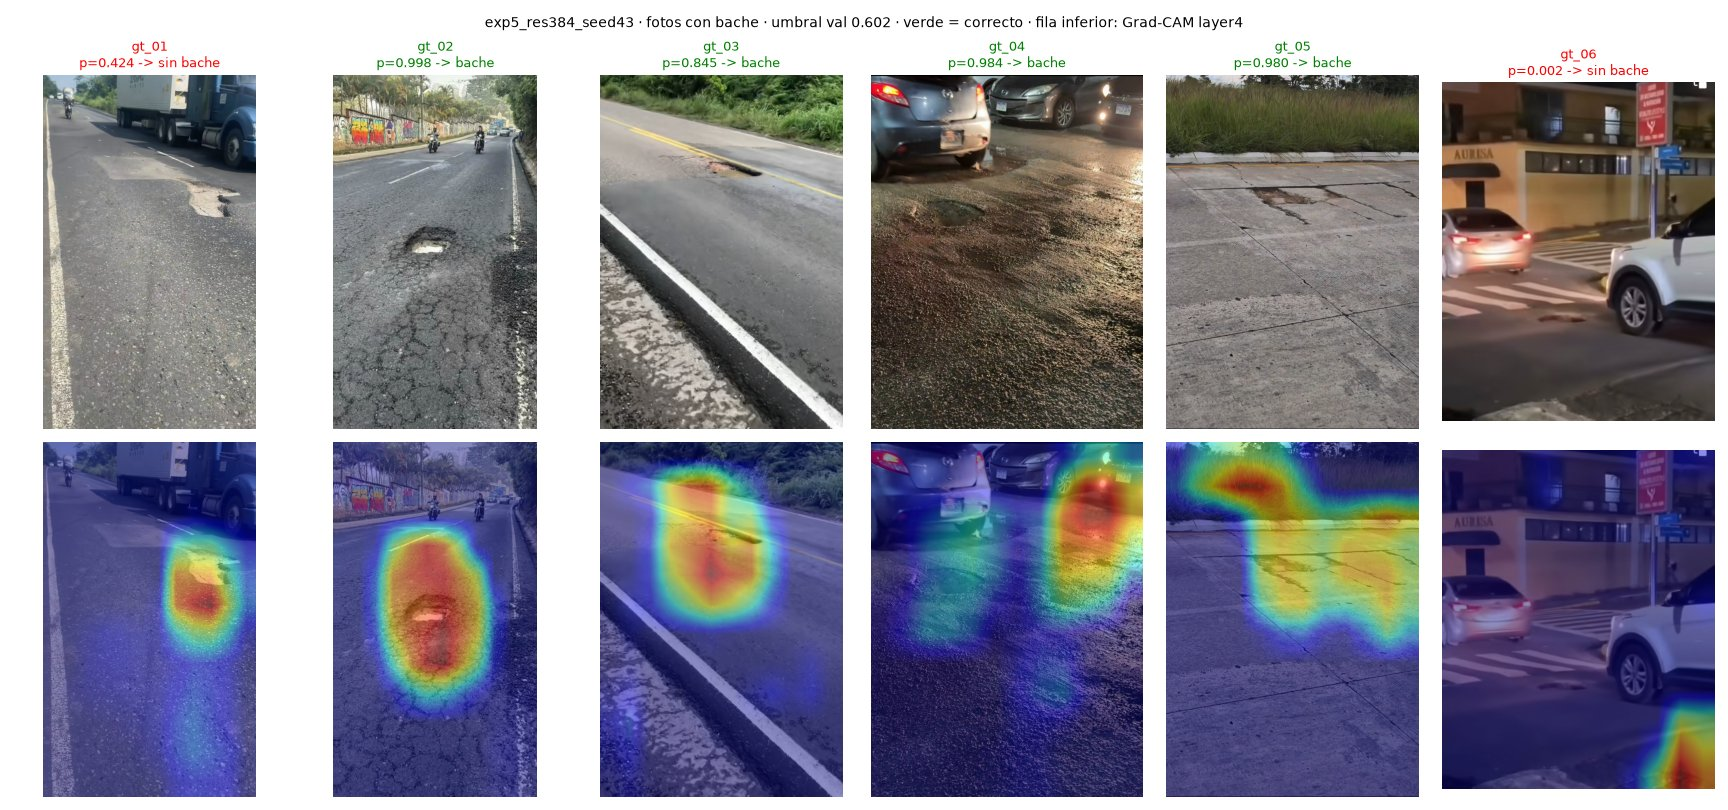

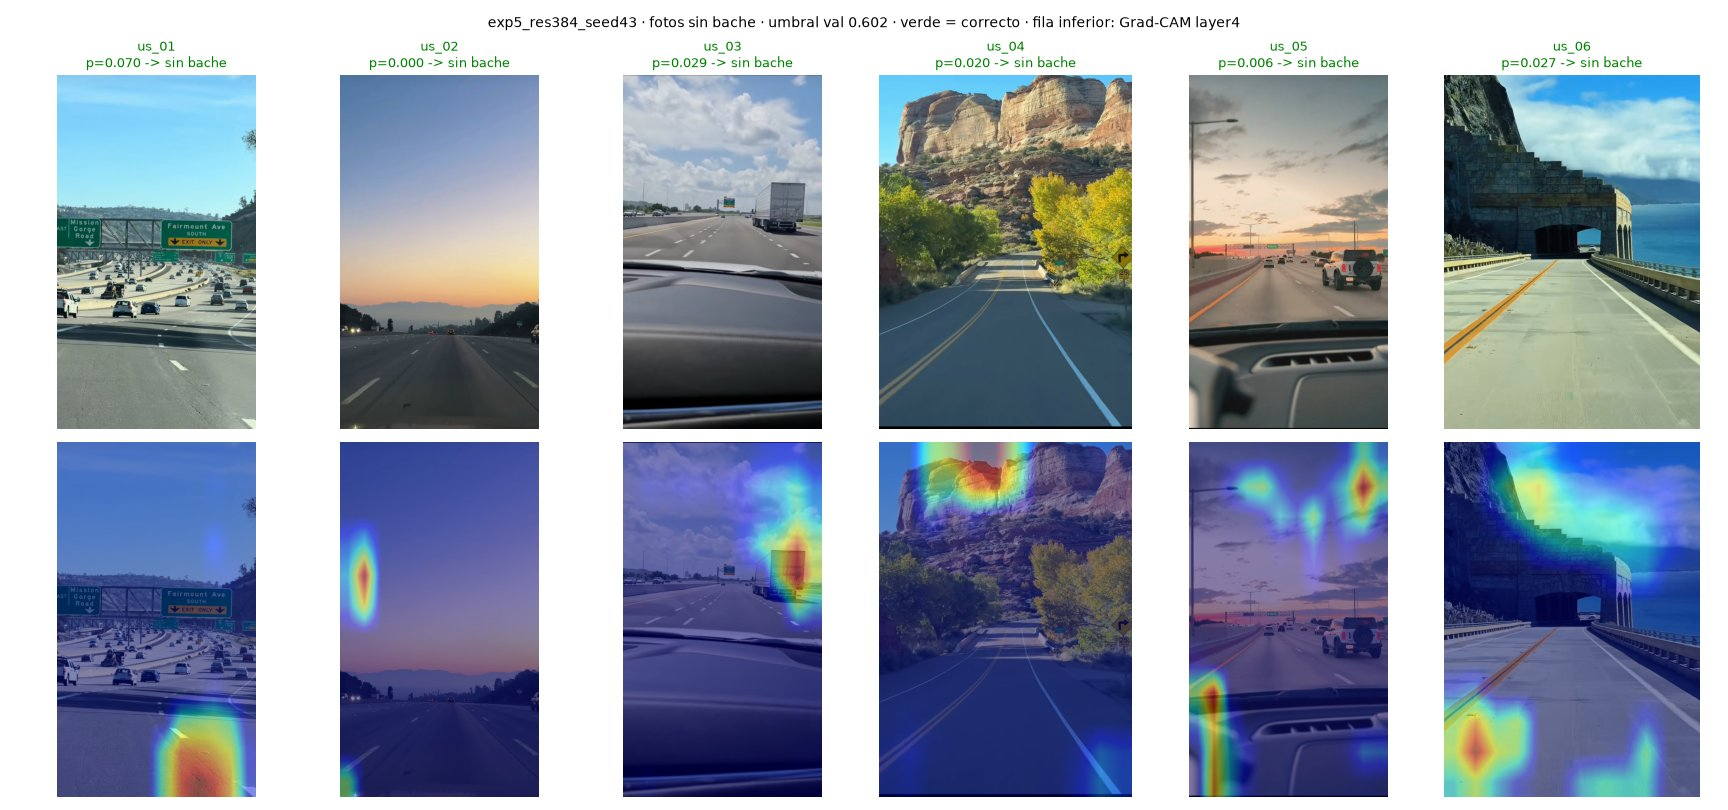

In [15]:
for name in ["gradcam_con_bache.jpg", "gradcam_sin_bache.jpg"]:
    if (EXT / name).exists():
        display(Image(filename=str(EXT / name), width=950))

**Lectura (modelo seleccionado `exp5_res384_seed43`): 4 de 6 baches detectados y 0 falsas alarmas en 6 fotos sin bache.**
- **Baches grandes, de día y cercanos (`gt_02`, `gt_03`):** detectados con Grad-CAM sobre el bache, como en RDD2022.
- **`gt_01` (bache con parche):** Grad-CAM cae sobre el bache, pero la probabilidad (0.42) no llega al umbral (0.60).
- **`gt_06` (bache pequeño, de noche, lejano):** ningún modelo lo detecta; es el mismo fallo que en Noruega (objeto
  de pocos píxeles tras el resize).
- **Aciertos por la razón equivocada:** en `gt_04` la activación está en los carros y faros, no en los baches; en
  `gt_05` (losas de concreto) sobre todo en el pasto y el bordillo.
- **Fotos sin bache:** probabilidades ≤ 0.07; en ellas Grad-CAM está normalizado por imagen y solo marca la zona menos
  negativa (camión, tablero), no un bache. La única falsa alarma es de `exp5_res384` (seed 42) en `us_01`, por su
  umbral de validación muy bajo (0.073).

Con 12 fotos esto es consistente con las conclusiones, pero no las mide: hace falta un conjunto guatemalteco revisado,
con negativos difíciles, evaluado con el umbral congelado.

## 11. Qué explica el desempeño y qué sigue sin resolverse

**1. Subir la resolución de 224 a 384 px es la mejora más clara del proyecto, y es reproducible.**
Con la misma ResNet18, mismos datos y mismo protocolo, `exp5_res384` (media ± desviación estándar de 3 seeds) obtiene
AP **0.822 ± 0.008 en validación** y **0.777 ± 0.016 en test interno**, frente a 0.763 y 0.707 del control a 224 px
(`exp2`). La mejora (~+0.06–0.07 AP) es varias veces mayor que la variación entre seeds. La hipótesis se formuló solo
con train: a 224 px la mitad de los baches queda con menos de 13 px de lado.

**2. Supera también a EfficientNet-B0 (224 px).** EfficientNet obtuvo AP 0.768 en validación y 0.731 en test interno;
`exp2` (ResNet18, 224 px) queda prácticamente empatado con ella (0.763 / 0.707). Es decir, a igual resolución la
arquitectura importa poco, y la resolución de entrada importa más. Según la regla del protocolo (máxima AP en
validación) el clasificador seleccionado es `exp5_res384_seed43` (AP val 0.829).

**2b. Las ablaciones a 224 px (una sola seed) no cambian la conclusión: lo que importa es el preentrenamiento y la resolución.**
Todas se comparan contra el control `exp2` (AP val 0.763) por AP en validación, nunca por test:
- **Desde cero (`exp1`, 30 épocas máx., lr 1e-3):** AP val **0.514** (test interno 0.487), mejor época 22. Sin los pesos
  de ImageNet el modelo queda muy por debajo; en dron (0.027) cae al nivel de la prevalencia. El preentrenamiento es
  la decisión de mayor impacto del proyecto (+0.25 AP en val).
- **Augmentation (`exp3`):** AP val **0.764**, +0.001 sobre `exp2`, dentro de la variación entre seeds medida en exp5
  (± 0.008): **empate**. Retrasa el sobreajuste (mejor época 7 frente a 2). En los tests la AP es 0.734 (interno) y 0.413
  (dron) frente a 0.707 y 0.271 de `exp2`, pero esos números no se usan para decidir y una sola seed no permite
  atribuir la diferencia a la técnica.
- **Tareas auxiliares D00/D10/D20 (`exp4`):** AP val **0.762**, −0.001 frente a `exp2`: **sin mejora**. Las cabezas
  auxiliares sí aprenden (AP val D00 0.778, D10 0.618, D20 0.764), pero no ayudan a la tarea D40.

**3. La generalización a otros dominios sigue sin resolverse.**
- **Noruega:** la AP sube de 0.054 (`exp2`) a 0.099 ± 0.013 y se detectan en promedio 32 de 256 baches (vs 4), pero
  el recall sigue cerca de 13 %. Los baches noruegos son los más pequeños del dataset (cajas ~0.1 % de la imagen) y
  las fotos tienen otra cámara, clima y paisaje (nieve, bosque).
- **China_Drone (vista aérea):** AP 0.321 ± 0.020 (vs 0.271), con muchas falsas alarmas.
- El umbral óptimo de validación varía mucho entre seeds (0.07–0.66) porque el modelo está **sobreconfiado** (la
  pérdida de validación crece mientras la AP mejora); por eso el F1 en dominios externos es inestable. Recalibrar el
  umbral con datos externos rompería el protocolo, así que no se hace.

**4. Grad-CAM: el modelo mira los baches más que el azar, pero no de forma fiable.** Sobre las mismas 822 imágenes con
bache, la activación cae dentro de las cajas D40 ~3–4 veces más de lo esperado para un mapa uniforme en test interno y
dron (mediana masa/área), pero el punto máximo cae dentro de una caja en solo 7–27 % de las imágenes, y en Noruega la
masa en las cajas es prácticamente nula. En los ejemplos aleatorios hay aciertos "por la razón equivocada" (activación en cielo, árboles o
señales). La mejora de exp5 en AP **no** se traduce en una localización claramente mejor; Grad-CAM de `layer4` es
grueso (12 × 12 celdas) y es un diagnóstico, no una prueba causal.

**5. Costo:** a 384 px la inferencia por imagen pasa de 4.6 a 6.3 ms en GPU (GTX 1650) y de 31 a 73 ms en CPU
(mediana, batch 1). Sigue siendo viable en tiempo real con GPU.

### Limitaciones
- El control `exp2`, las ablaciones `exp1`, `exp3`, `exp4` y EfficientNet tienen **una sola seed**; diferencias de
  ~0.001 AP en validación (exp3, exp4 frente a exp2) no son distinguibles del ruido entre seeds.
- Las ablaciones se hicieron a 224 px; no se probó augmentation ni tareas auxiliares combinadas con 384 px.
- `exp1` y `exp4` se entrenaron con `num_workers: 2` (en vez de 4) por falta de RAM; solo afecta la carga de datos,
  no el protocolo.
- La latencia de EfficientNet se midió en otro equipo y no es comparable.
- No hay evaluación formal en Guatemala todavía. La prueba con 12 fotos externas (sección 10) detecta 4 de 6
  baches guatemaltecos sin falsas alarmas en negativos fáciles, pero es demasiado pequeña y sin revisión para
  demostrar generalización a vías guatemaltecas.

### Siguientes pasos sugeridos
Probar 448–512 px (la tendencia sugiere más ganancia), augmentation que no recorte baches, y un **detector de objetos**
(p. ej. YOLO) que use las cajas D40 durante el entrenamiento: hoy el clasificador nunca ve dónde está el bache, solo si
la foto lo contiene.
